In [1]:
pip install torch torchvision matplotlib numpy scikit-learn captum grad-cam


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import os

sys.path.append(
    '/Users/zeynepoykuerdem/master_thesis/master_thesis'
)

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

print(f"PyTorch version: {torch.__version__}")
device = torch.device(
    "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
print(f"Using device: {device}")

PyTorch version: 2.10.0
Using device: mps


In [4]:
from data.cifar10_loader import load_cifar10_data,train_data_loader, test_data_loader

train_data,test_data=load_cifar10_data()
batch_size=64

#Loader
train_loader=train_data_loader(train_data,batch_size)
test_loader=test_data_loader(test_data,batch_size)

# Test
images, labels = next(iter(train_loader))
print(f"Batch shape: {images.shape}")
print(f"Labels shape: {labels.shape}")

Using device: mps


/Users/zeynepoykuerdem/.pyenv/versions/thesis_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Batch shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])


In [3]:
from models.cnn_model import SimpleCNN
model = SimpleCNN(num_classes=10).to(device)

In [5]:

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torch.autograd import backward


loss_function=nn.CrossEntropyLoss()
optimizer= torch.optim.SGD(
    model.parameters(),
    lr=0.001,
    weight_decay=0.005,
    momentum=0.9)

history={
    'train_loss' :[],
    'train_acc':[]
}

num_epochs=50
for epoch in range (num_epochs):
    model.train()
    correct =0
    total =0
    epoch_loss =0
    for images,labels in train_loader:
        images=images.to(device)
        labels=labels.to(device)
        
        #forward pass
        outputs=model(images)
        loss= loss_function(outputs,labels)
        
        optimizer.zero_grad()# reset the gradients all optimized
        # backward pass and optimize
        loss.backward()
        optimizer.step()

        #Accuracy
        epoch_loss+= loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total   += labels.size(0)
        correct += (predicted == labels).sum().item()
        
    avg_loss= epoch_loss/ len(train_loader)
    accuracy = 100*correct/total
    history['train_acc'].append(accuracy)
    history['train_loss'].append(avg_loss)

    
    if(epoch + 1)%10==0:
        print(f"Epoch[{epoch+1}/{num_epochs}]"
              f"Loss:{avg_loss:.4f}"f"Accuracy:{accuracy:.2f}")
        
    
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss
ax1.plot(history['train_loss'], label='Train Loss', color='blue')
ax1.set_title('Training Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

# Accuracy
ax2.plot(history['train_acc'], label='Train Accuracy', color='green')
ax2.set_title('Training Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()

plt.tight_layout()
plt.savefig('/Users/zeynepoykuerdem/master_thesis/figures/training_history.png')
plt.show()


KeyboardInterrupt: 

In [4]:
print(f"Device:{device}")
print(f"MPS Available : {torch.backends.mps.is_available()}")

Device:mps
MPS Available : True


Epoch_number= 20 →50
learning_rate=0.001 → 0.01

In [4]:
def train_experiment(exp_model, loader, num_epochs=100):
    exp_optimizer = torch.optim.SGD(
        exp_model.parameters(),
        lr=0.01,
        weight_decay=0.005,
        momentum=0.9
    )
    exp_loss_fn = nn.CrossEntropyLoss()

    history = {'loss': [], 'acc': []}

    for epoch in range(num_epochs):
        exp_model.train()
        correct    = 0
        total      = 0
        epoch_loss = 0.0

        for (images, labels)in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = exp_model(images)
            loss    = exp_loss_fn(outputs, labels)

            exp_optimizer.zero_grad()
            loss.backward()
            exp_optimizer.step()

            epoch_loss   += loss.item()
            _, predicted  = torch.max(outputs.data, 1)
            total        += labels.size(0)
            correct      += (predicted == labels).sum().item()

        avg_loss = epoch_loss / len(loader)
        accuracy = 100.0 * correct / total

        history['loss'].append(avg_loss)
        history['acc'].append(accuracy)

        if (epoch + 1) % 10 == 0:
            print(f"  Epoch [{epoch+1}/{num_epochs}]  "
                  f"Loss: {avg_loss:.4f}  "
                  f"Accuracy: {accuracy:.2f}%")

    return history

In [5]:
def evaluate_model(loader,model):
    eval_model=model
    eval_model.eval()
    correct    = 0
    total      = 0
    epoch_loss = 0.0

    exp_loss_fn = nn.CrossEntropyLoss()

    

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            y_pred = eval_model(images)
            loss   = exp_loss_fn(y_pred, labels)

            epoch_loss   += loss.item()
            _, predicted  = torch.max(y_pred.data, 1)
            total        += labels.size(0)
            correct      += (predicted == labels).sum().item()

    avg_loss = epoch_loss / len(loader)
    accuracy = 100.0 * correct / total

    return accuracy, avg_loss








## Zhang et al. (2021) Experiment
Label Shuffling and Random Pixels — demonstrating memorization effect

"Most of our randomization tests are performed with
explicit regularization turned off"


In [6]:

from data.nosiy_data import ZhangExperiment
from torch.utils.data import DataLoader,Subset
from data.cifar10_loader import load_cifar10_data_no_augmentation
from evaluation.plotting import (
    plot_history,plot_label_corruption_vs_time_to_overfit,plot_training_loss_curves,plot_label_corruption_vs_test_error,gradcam_visualization,integrated_gradients_visualization
)

train_base,test_base=load_cifar10_data_no_augmentation()
subset_indices= list(range(500))
train_subset=Subset(train_base,subset_indices)


true_dataset= ZhangExperiment(train_subset,'true')

random_labels= ZhangExperiment(train_subset,'random_labels')

random_pixels= ZhangExperiment(train_subset,'random_pixels')

test_base_loader= DataLoader(test_base,batch_size=32,shuffle=False)




Using device: mps


In [7]:
experiments={
    'true_labels': ZhangExperiment(train_subset,'true_labels'),
    'random_labels': ZhangExperiment(train_subset,'random_labels'),
    'random_pixels': ZhangExperiment(train_subset,'random_pixels'),
    }

results_cnn={}



for exp_name, exp_dataset in experiments.items():
    print(f"\nExperiment: {exp_name}")
    exp_loader = DataLoader(exp_dataset, batch_size=32, shuffle=True)
    # No regularization for CNN
    exp_model = SimpleCNN(num_classes=10).to(device)

    history = train_experiment(exp_model, exp_loader)

    test_acc, test_loss = evaluate_model(test_base_loader, exp_model)

    results_cnn[exp_name] = {
        'loss_curve': history['loss'],
        'train_acc': history['acc'][-1],
        'train_loss': history['loss'][-1],
        'test_acc': test_acc,
        'test_loss': test_loss
    }
    print(f"  Train: {history['acc'][-1]:.2f}%  Test: {test_acc:.2f}%")
    



Experiment: true_labels
  Epoch [10/100]  Loss: 2.0895  Accuracy: 23.80%
  Epoch [20/100]  Loss: 1.8148  Accuracy: 37.00%
  Epoch [30/100]  Loss: 1.5760  Accuracy: 41.80%
  Epoch [40/100]  Loss: 0.7135  Accuracy: 76.20%
  Epoch [50/100]  Loss: 0.2431  Accuracy: 93.40%
  Epoch [60/100]  Loss: 0.3328  Accuracy: 93.40%
  Epoch [70/100]  Loss: 0.0053  Accuracy: 100.00%
  Epoch [80/100]  Loss: 0.0066  Accuracy: 100.00%
  Epoch [90/100]  Loss: 0.0090  Accuracy: 100.00%
  Epoch [100/100]  Loss: 0.0108  Accuracy: 100.00%
  Train: 100.00%  Test: 35.26%

Experiment: random_labels
  Epoch [10/100]  Loss: 2.2984  Accuracy: 11.20%
  Epoch [20/100]  Loss: 2.2913  Accuracy: 11.20%
  Epoch [30/100]  Loss: 2.2638  Accuracy: 15.60%
  Epoch [40/100]  Loss: 2.1926  Accuracy: 20.60%
  Epoch [50/100]  Loss: 2.0621  Accuracy: 23.20%
  Epoch [60/100]  Loss: 1.8106  Accuracy: 36.80%
  Epoch [70/100]  Loss: 1.0554  Accuracy: 62.20%
  Epoch [80/100]  Loss: 0.2185  Accuracy: 94.00%
  Epoch [90/100]  Loss: 0.1093

## Plotting training loss vs steps

In [9]:
print(results_cnn.keys())
print(results_cnn[list(results_cnn.keys())[0]].keys())

dict_keys(['true_labels', 'random_labels', 'random_pixels'])
dict_keys(['loss_curve', 'train_acc', 'train_loss', 'test_acc', 'test_loss'])


Saved: /Users/zeynepoykuerdem/master_thesis/figures/cnn_training_loss_curves.png


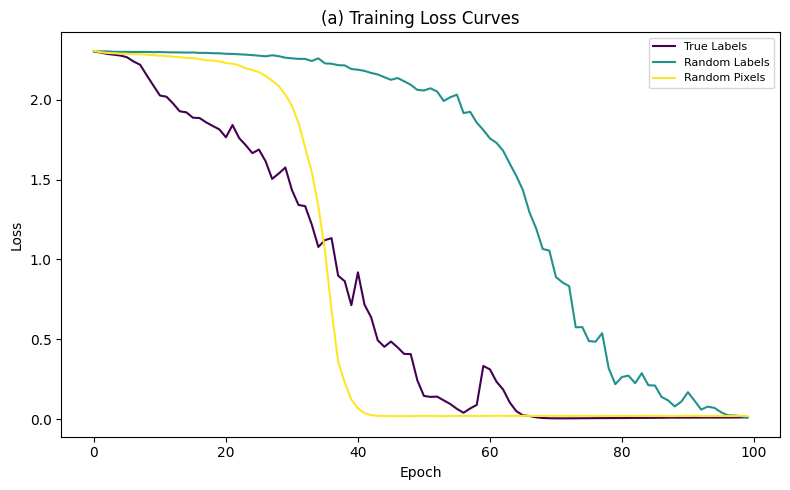

In [10]:
from evaluation.plotting import plot_training_loss_curves

plot_training_loss_curves(results_cnn, list(results_cnn.keys()), save_path='/Users/zeynepoykuerdem/master_thesis/figures/cnn_training_loss_curves.png')

In [24]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


def get_target_layer(model, model_name='simple'):
    '''
    model_name: 'simple' fro SimpleCNN,'resnet' for ResNet56
    '''

    if model_name == 'simple':
        return model.block3[0]
    elif model_name == 'resnet':
        return model.layer3[-1].conv2
    
def gradcam_visualization(model , test_loader, device, target_layer):

    model.eval()

    grad_cam= GradCAM( model=model, target_layers=[target_layer])

    #test_batch
    test_images,test_labels= next(iter(test_loader))
    test_images=test_images.to(device)
    test_labels=test_labels.to(device)

    input_tensor = test_images[0].unsqueeze(0).to(device)#single image
    targets = [ClassifierOutputTarget(test_labels[0].item())]

    grayscale_cam= grad_cam(input_tensor=input_tensor,targets=targets)
    grayscale_cam= grayscale_cam[0,:]
    print(f"Grayscale CAM min: {grayscale_cam.min()}, max: {grayscale_cam.max()}")

    # Conver the input image from normalized tensor to image format
    mean     = np.array([0.4914, 0.4822, 0.4465]).reshape(1,1,3)
    std      = np.array([0.2023, 0.1994, 0.2010]).reshape(1,1,3)

    image_show=test_images[0].cpu().numpy().transpose(1,2,0) * std + mean

    image_show = np.clip(image_show, 0, 1).astype(np.float32)


    visualization = show_cam_on_image(image_show, grayscale_cam[0], use_rgb=True)
    plt.imshow(visualization)
    plt.show()







 Corruption Ratio: 0.0
  Epoch [10/100]  Loss: 2.0445  Accuracy: 26.00%
  Epoch [20/100]  Loss: 1.8357  Accuracy: 35.80%
  Epoch [30/100]  Loss: 1.5445  Accuracy: 44.00%
  Epoch [40/100]  Loss: 0.9469  Accuracy: 67.20%
  Epoch [50/100]  Loss: 0.4372  Accuracy: 86.60%
  Epoch [60/100]  Loss: 0.0857  Accuracy: 98.00%
  Epoch [70/100]  Loss: 0.0065  Accuracy: 100.00%
  Epoch [80/100]  Loss: 0.0082  Accuracy: 100.00%
  Epoch [90/100]  Loss: 0.0109  Accuracy: 100.00%
  Epoch [100/100]  Loss: 0.0141  Accuracy: 100.00%
 SimpleCNN - Train Acc: 100.00%, Test Acc: 34.29%
Grayscale CAM min: 0.0, max: 0.9999998807907104


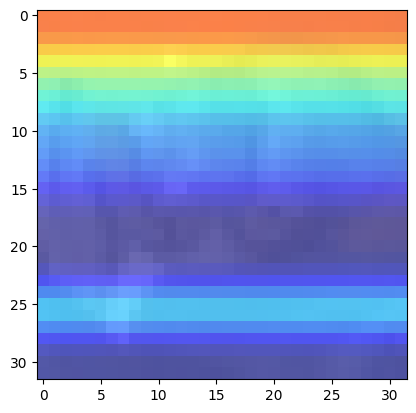

 Training ResNet56 on corrupted data with ratio 0.0...


Using cache found in /Users/zeynepoykuerdem/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master


  Epoch [10/100]  Loss: 1.6405  Accuracy: 41.00%
  Epoch [20/100]  Loss: 0.8481  Accuracy: 69.60%
  Epoch [30/100]  Loss: 0.1201  Accuracy: 96.80%
  Epoch [40/100]  Loss: 0.1652  Accuracy: 94.80%
  Epoch [50/100]  Loss: 0.1174  Accuracy: 96.40%
  Epoch [60/100]  Loss: 0.0385  Accuracy: 98.80%
  Epoch [70/100]  Loss: 0.0886  Accuracy: 98.00%
  Epoch [80/100]  Loss: 0.0051  Accuracy: 100.00%
  Epoch [90/100]  Loss: 0.0099  Accuracy: 100.00%
  Epoch [100/100]  Loss: 0.0072  Accuracy: 100.00%
 ResNet56 - Train Acc: 100.00%, Test Acc: 34.48%
Grayscale CAM min: 0.0, max: 0.9999998807907104


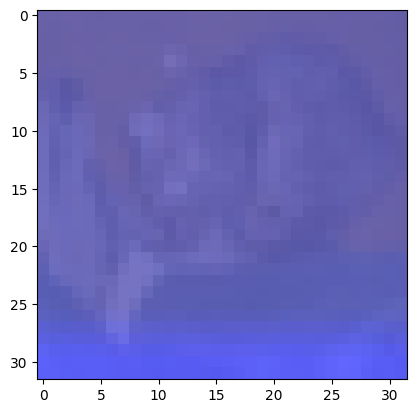


 Corruption Ratio: 0.25
  Epoch [10/100]  Loss: 2.2322  Accuracy: 17.60%
  Epoch [20/100]  Loss: 2.0510  Accuracy: 26.40%
  Epoch [30/100]  Loss: 1.9231  Accuracy: 32.60%
  Epoch [40/100]  Loss: 1.6011  Accuracy: 43.60%
  Epoch [50/100]  Loss: 0.8551  Accuracy: 73.60%
  Epoch [60/100]  Loss: 0.1754  Accuracy: 95.00%
  Epoch [70/100]  Loss: 0.0522  Accuracy: 98.80%
  Epoch [80/100]  Loss: 0.0049  Accuracy: 100.00%
  Epoch [90/100]  Loss: 0.0073  Accuracy: 100.00%
  Epoch [100/100]  Loss: 0.0098  Accuracy: 100.00%
 SimpleCNN - Train Acc: 100.00%, Test Acc: 27.97%
Grayscale CAM min: 0.0, max: 0.9999998807907104


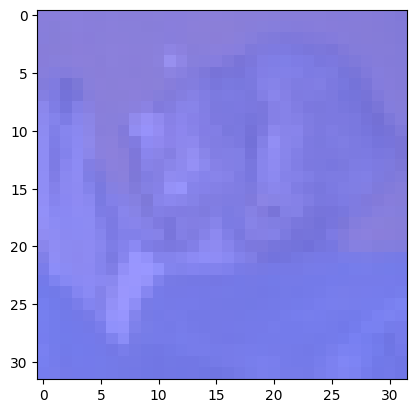

 Training ResNet56 on corrupted data with ratio 0.25...


Using cache found in /Users/zeynepoykuerdem/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master


  Epoch [10/100]  Loss: 1.9433  Accuracy: 30.20%
  Epoch [20/100]  Loss: 1.0872  Accuracy: 62.20%
  Epoch [30/100]  Loss: 0.3626  Accuracy: 89.20%
  Epoch [40/100]  Loss: 0.0782  Accuracy: 98.00%
  Epoch [50/100]  Loss: 0.0297  Accuracy: 99.20%
  Epoch [60/100]  Loss: 0.2158  Accuracy: 93.40%
  Epoch [70/100]  Loss: 0.1337  Accuracy: 95.80%
  Epoch [80/100]  Loss: 0.0049  Accuracy: 100.00%
  Epoch [90/100]  Loss: 0.0084  Accuracy: 100.00%
  Epoch [100/100]  Loss: 0.0054  Accuracy: 100.00%
 ResNet56 - Train Acc: 100.00%, Test Acc: 26.68%
Grayscale CAM min: 0.0, max: 0.9999998807907104


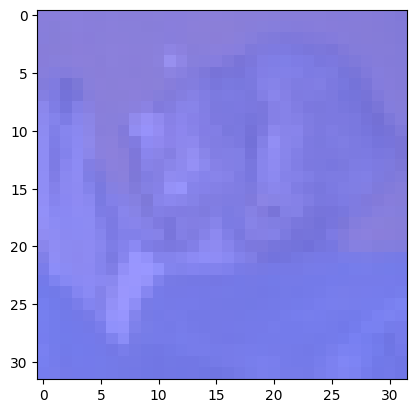


 Corruption Ratio: 0.5
  Epoch [10/100]  Loss: 2.2879  Accuracy: 13.80%
  Epoch [20/100]  Loss: 2.2169  Accuracy: 18.00%
  Epoch [30/100]  Loss: 2.1830  Accuracy: 21.40%
  Epoch [40/100]  Loss: 2.0321  Accuracy: 28.40%
  Epoch [50/100]  Loss: 1.6067  Accuracy: 43.20%
  Epoch [60/100]  Loss: 0.9475  Accuracy: 68.20%
  Epoch [70/100]  Loss: 0.1825  Accuracy: 94.00%
  Epoch [80/100]  Loss: 0.1126  Accuracy: 96.00%
  Epoch [90/100]  Loss: 0.0040  Accuracy: 100.00%
  Epoch [100/100]  Loss: 0.0050  Accuracy: 100.00%
 SimpleCNN - Train Acc: 100.00%, Test Acc: 20.96%
Grayscale CAM min: 0.0, max: 0.9999998807907104


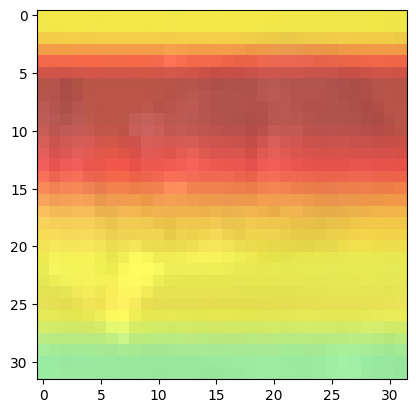

 Training ResNet56 on corrupted data with ratio 0.5...


Using cache found in /Users/zeynepoykuerdem/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master


  Epoch [10/100]  Loss: 2.1703  Accuracy: 19.40%
  Epoch [20/100]  Loss: 1.7269  Accuracy: 39.00%
  Epoch [30/100]  Loss: 0.9303  Accuracy: 66.60%
  Epoch [40/100]  Loss: 0.2541  Accuracy: 92.40%
  Epoch [50/100]  Loss: 0.3780  Accuracy: 87.20%
  Epoch [60/100]  Loss: 0.0076  Accuracy: 100.00%
  Epoch [70/100]  Loss: 0.0035  Accuracy: 100.00%
  Epoch [80/100]  Loss: 0.0075  Accuracy: 100.00%
  Epoch [90/100]  Loss: 0.0053  Accuracy: 100.00%
  Epoch [100/100]  Loss: 0.0052  Accuracy: 100.00%
 ResNet56 - Train Acc: 100.00%, Test Acc: 21.06%
Grayscale CAM min: 0.0, max: 0.9999998807907104


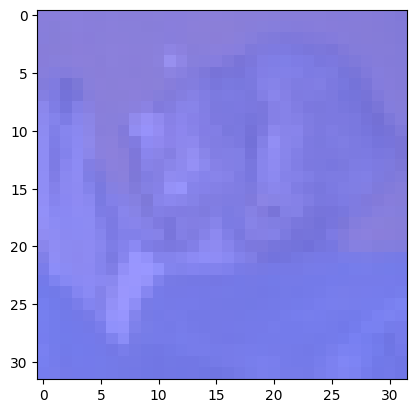


 Corruption Ratio: 0.75
  Epoch [10/100]  Loss: 2.2938  Accuracy: 15.40%
  Epoch [20/100]  Loss: 2.2729  Accuracy: 15.80%
  Epoch [30/100]  Loss: 2.2239  Accuracy: 19.20%
  Epoch [40/100]  Loss: 2.1132  Accuracy: 23.60%
  Epoch [50/100]  Loss: 1.8993  Accuracy: 32.20%
  Epoch [60/100]  Loss: 1.2910  Accuracy: 55.80%
  Epoch [70/100]  Loss: 0.3114  Accuracy: 91.00%
  Epoch [80/100]  Loss: 0.0609  Accuracy: 98.40%
  Epoch [90/100]  Loss: 0.0043  Accuracy: 100.00%
  Epoch [100/100]  Loss: 0.0058  Accuracy: 100.00%
 SimpleCNN - Train Acc: 100.00%, Test Acc: 15.69%
Grayscale CAM min: 0.0, max: 0.9999998807907104


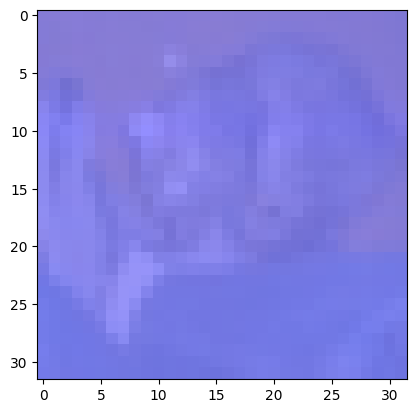

 Training ResNet56 on corrupted data with ratio 0.75...


Using cache found in /Users/zeynepoykuerdem/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master


  Epoch [10/100]  Loss: 2.2123  Accuracy: 17.40%
  Epoch [20/100]  Loss: 1.9052  Accuracy: 34.80%
  Epoch [30/100]  Loss: 0.5714  Accuracy: 82.40%
  Epoch [40/100]  Loss: 0.2604  Accuracy: 92.20%
  Epoch [50/100]  Loss: 0.1190  Accuracy: 96.60%
  Epoch [60/100]  Loss: 0.0790  Accuracy: 98.20%
  Epoch [70/100]  Loss: 0.0045  Accuracy: 100.00%
  Epoch [80/100]  Loss: 0.0041  Accuracy: 100.00%
  Epoch [90/100]  Loss: 0.0063  Accuracy: 100.00%
  Epoch [100/100]  Loss: 0.0042  Accuracy: 100.00%
 ResNet56 - Train Acc: 100.00%, Test Acc: 15.95%
Grayscale CAM min: 0.0, max: 0.9999998807907104


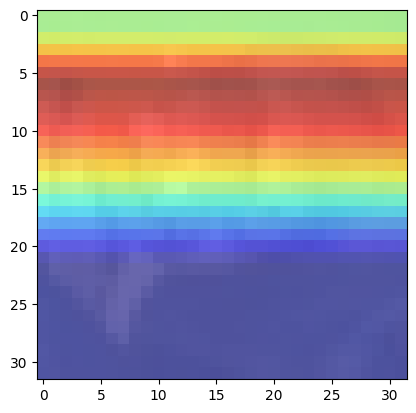


 Corruption Ratio: 1.0
  Epoch [10/100]  Loss: 2.2952  Accuracy: 12.60%
  Epoch [20/100]  Loss: 2.2892  Accuracy: 11.00%
  Epoch [30/100]  Loss: 2.2669  Accuracy: 14.80%
  Epoch [40/100]  Loss: 2.2160  Accuracy: 18.40%
  Epoch [50/100]  Loss: 2.1582  Accuracy: 24.60%
  Epoch [60/100]  Loss: 1.8994  Accuracy: 32.40%
  Epoch [70/100]  Loss: 1.4251  Accuracy: 50.60%


KeyboardInterrupt: 

In [25]:
from data.nosiy_data import ZhangExperiment
from torch.utils.data import DataLoader
'''
0% corruption
50% corruption
100% corruption
'''
corruption_levels = [0.0,0.25,0.5,0.75,1.0]
results_cnn ={}
results_resnet={}

for ratio in corruption_levels:
    print(f"\n Corruption Ratio: {ratio}")
    exp_dataset= ZhangExperiment(true_dataset,'random_labels',noise_ratio=ratio)

    exp_loader=DataLoader(exp_dataset, batch_size=32, shuffle=True)

    exp_model=SimpleCNN(num_classes=10).to(device)
    ''' Train the model on the current corruption level and store the history'''
    history = train_experiment(exp_model, exp_loader, num_epochs=100)

    '''
    Evaluate the model on the clean test set and store the results
    '''

    test_acc,test_loss= evaluate_model(test_base_loader,exp_model) # burda eval calistiriyoruz cunku test_base_loader temiz veri icermekte

    results_cnn[ratio]={
        'loss_history' : history['loss'],
        'train_acc': history['acc'][-1],
        'train_loss': history['loss'][-1],
        'test_acc': test_acc,
        'test_loss': test_loss
    }

    print(f" SimpleCNN - Train Acc: {history['acc'][-1]:.2f}%, Test Acc: {test_acc:.2f}%")
    
    gradcam_visualization(exp_model, test_base_loader, device, get_target_layer(exp_model, model_name='simple'))

    print(f" Training ResNet56 on corrupted data with ratio {ratio}...")

    resnet56 = torch.hub.load("chenyaofo/pytorch-cifar-models",
    "cifar10_resnet56", pretrained=False)
    resnet_model = resnet56.to(device)

    resnet_history= train_experiment(resnet_model,exp_loader,num_epochs=100)

    resnet_test_acc,resnet_test_loss=evaluate_model(test_base_loader,resnet_model)

    results_resnet[ratio]={
        'loss_history': resnet_history['loss'],
        'train_acc': resnet_history['acc'][-1],
        'train_loss': resnet_history['loss'][-1],
        'test_acc': resnet_test_acc,
        'test_loss': resnet_test_loss
    }

    print(f" ResNet56 - Train Acc: {resnet_history['acc'][-1]:.2f}%, Test Acc: {resnet_test_acc:.2f}%")

    gradcam_visualization(resnet_model, test_base_loader, device, get_target_layer(resnet_model, model_name='resnet'))

## Plotting Corruption Experiment
Time_to_overfit vs Label Corruption
Test_error vs Label Corruption
ResNet56 vs Simple CNN Structure (Without Regulators)

Saved: /Users/zeynepoykuerdem/master_thesis/figures/cnn_time_to_overfit.png


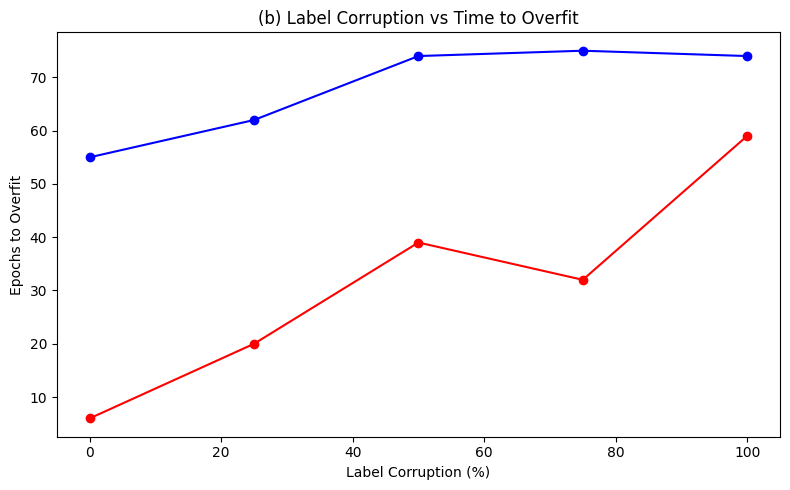

Saved: /Users/zeynepoykuerdem/master_thesis/figures/cnn_test_error.png


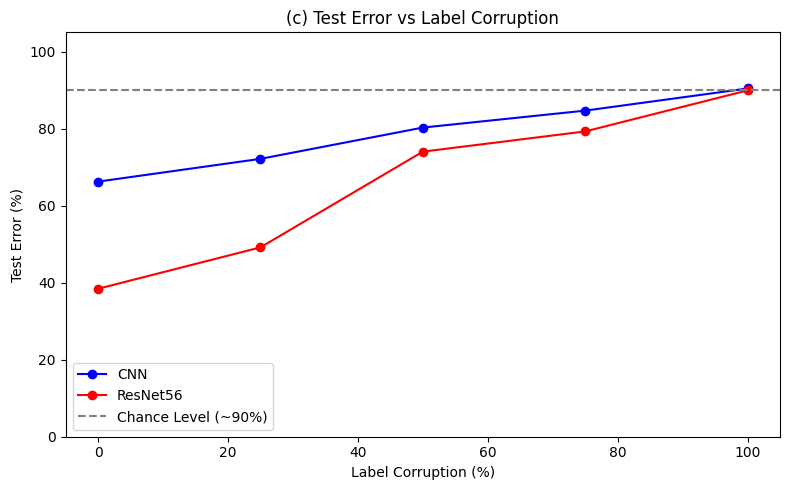

In [15]:
#results_cnn,results_resnet,corruption_levels

from evaluation.plotting import plot_label_corruption_vs_time_to_overfit,plot_label_corruption_vs_test_error

plot_label_corruption_vs_time_to_overfit(results_cnn,results_resnet,corruption_levels, save_path='/Users/zeynepoykuerdem/master_thesis/figures/cnn_time_to_overfit.png')

plot_label_corruption_vs_test_error(results_cnn,results_resnet,corruption_levels, save_path='/Users/zeynepoykuerdem/master_thesis/figures/cnn_test_error.png')

Train Model by each experiment's
Training Loss and Training Accuracy

## Predicted Class

## Grad-Cam Implementation

1- Determine the target layer
2- Compute the most probable class
3- Gradient of the most probable class
4- Pool the gradients
5- Weight Channels by corresponding pool gradients
6- Heatmap

## Adversarial Attacks

In [ ]:
from attacks.fgsm import fgsm_attack
from attacks.pgd import pgd_attack

